# Sign language letters with a CNN

A CNN with BatchNorm and Dropout trained on the Sign Language MNIST dataset (28x28 grayscale hand sign images). At the end there is a plot of train and test accuracy per epoch and a confusion matrix.

In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

In [89]:
dfX_train = pd.read_csv("sign_mnist_train.csv")
dfX_test = pd.read_csv("sign_mnist_test.csv")

In [90]:
X_train1 = dfX_train.iloc[:, 1:].to_numpy()
y_train1 = dfX_train.iloc[:, 0].to_numpy()
X_test1 = dfX_test.iloc[:, 1:].to_numpy()
y_test1 = dfX_test.iloc[:, 0].to_numpy()
X_train = torch.tensor(X_train1, dtype=torch.float32).view(-1, 1, 28, 28)
y_train = torch.tensor(y_train1, dtype=torch.int64)
X_test = torch.tensor(X_test1, dtype=torch.float32).view(-1, 1, 28, 28)
y_test = torch.tensor(y_test1, dtype=torch.int64)

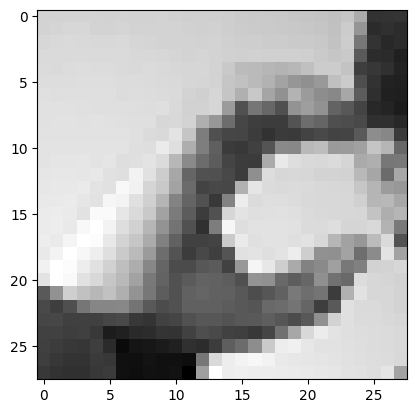

tensor(2)

In [92]:
img = X_train[3].reshape(28, 28)
plt.imshow(img, cmap='gray')
plt.show()
y_train[2]

In [94]:
class CNN(nn.Module):
    def __init__(self, num_classes=25):
        super().__init__()
        self.conv_sequential = nn.Sequential(
            # | 1 x 28 x 28
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # | 32 x 14 x 14
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # | 64 x 7 x 7
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
            # | 128 x 7 x 7
        )

        self.linear_sequential = nn.Sequential(
            # | Регуляризация
            nn.Dropout(0.5),
            # | 128 * 7 * 7
            nn.Linear(128 * 7 * 7, 512),
            nn.ReLU(),
            # | 512
            nn.Linear(512, num_classes)
            # | nc
        )

    def forward(self, x):
        x = self.conv_sequential(x)
        # Преобразуем тензор для полносвязного слоя
        x = x.view(-1, 128 * 7 * 7)
        x = self.linear_sequential(x)
        return x

# Пример создания модели
NN = CNN(num_classes=25)
NN.to('cuda')

CNN(
  (conv_sequential): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
  )
  (linear_sequential): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=6272, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=25, bias=True)
  )
)

In [96]:
def _init_weights(self):
    for m in self.modules():
        if isinstance(m, nn.Linear):
            # Kaiming is optimized specifically for ReLU/LeakyReLU
            nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='leaky_relu')
#NN.apply(_init_weights)

In [97]:
X_train = X_train.to('cuda')
y_train = y_train.to('cuda')
X_test = X_test.to('cuda')
y_test = y_test.to('cuda')
train = TensorDataset(X_train, y_train)
loader = DataLoader(train, batch_size = 32, shuffle=True, drop_last = True)

In [ ]:
epochs = 20
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(NN.parameters(), lr=0.0001, betas = (0.9, 0.99), weight_decay = 0)
test_acc = []
train_acc = [] # This will now store per-epoch average training accuracy

for epoch in range(epochs):
  print(epoch)
  NN.train() # Set model to training mode at the start of each epoch
  epoch_train_correct = 0
  epoch_train_total = 0

  for index, (X_tr, y_tr) in enumerate(loader):
    # X_tr and y_tr are already on 'cuda' from cell 7hXTxmGidBCZ
    y_pred = NN(X_tr)
    loss = loss_function(y_pred, y_tr)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step() # optimizer.step() should not be within torch.no_grad()

    with torch.no_grad(): # Use no_grad for accuracy calculation to save memory
      # Calculate batch training accuracy for accumulation
      predictions_tr = y_pred.argmax(dim=1) # Get predicted class labels
      total_batch = y_tr.size(0)
      correct_batch = (y_tr == predictions_tr).sum().item()

      epoch_train_correct += correct_batch
      epoch_train_total += total_batch

  # Calculate and append average training accuracy for the current epoch
  current_epoch_train_acc = 100 * epoch_train_correct / epoch_train_total
  train_acc.append(current_epoch_train_acc)

  ## Evaluation phase
  NN.eval() # Set model to evaluation mode
  with torch.no_grad():
    # X_test and y_test are already on 'cuda' from cell 7hXTxmGidBCZ
    outs = NN(X_test)
    predictions = torch.argmax(outs, dim=1)
    total = y_test.size(0)
    correct = (y_test==predictions).sum().item()
    acc = 100*correct/total
    test_acc.append(acc)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15


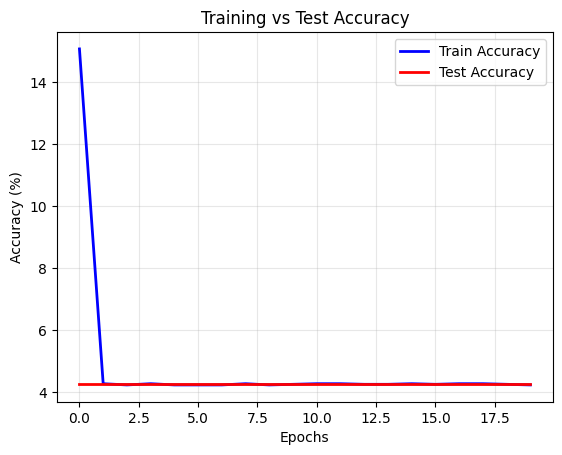

In [68]:
plt.plot(range(epochs), train_acc, color='blue', label='Train Accuracy', linewidth=2)
plt.plot(range(epochs), test_acc, color='red', label='Test Accuracy', linewidth=2)


plt.title('Training vs Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend() # This is crucial to show which color is which
plt.grid(True, alpha=0.3)

# 5. Display
plt.show()

In [93]:
X_train.shape

torch.Size([5181, 1, 28, 28])

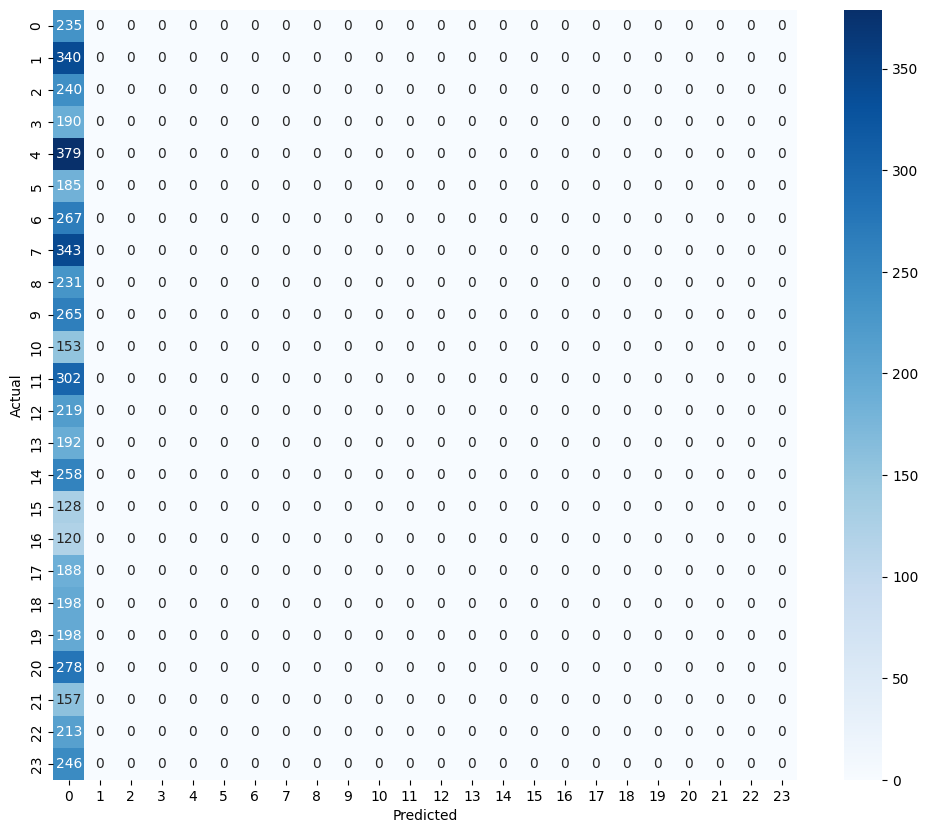

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
import torch

with torch.no_grad():
    # .argmax(1) turns the 25 outputs into a single class number (0-24)
    y_p_tensor = NN(X_test).argmax(1)

# 2. Convert both to NumPy
y_p = y_p_tensor.cpu().numpy()
y_t = y_test.cpu().numpy() # Assuming y_test is a Pandas Series/NumPy

# 3. Create and Plot
cm = confusion_matrix(y_t, y_p) # Order should be (True, Predicted)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()